# Classical Machine Learning Models

## Objective

Train and evaluate classical machine-learning models to predict students' final academic outcomes using a provisional feature set intended to represent information available at enrollment.

This notebook will:

1. Load the original dataset.
2. Reproduce the documented feature exclusions.
3. Create a stratified train/test split.
4. Build a preprocessing pipeline.
5. Train logistic regression as the first predictive model.
6. Compare its performance with a simple baseline.

The test set will be held out from model fitting and preprocessing.

In [22]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [2]:
project_root = Path.cwd().parent
data_path = project_root / "data" / "raw" / "data.csv"

df = pd.read_csv(data_path, sep=";")
df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## Feature Selection

The target is `Target`, containing the three final outcomes: Graduate, Dropout, and Enrolled.

For this initial experiment, we exclude:

- All first- and second-semester features, because they describe information recorded after enrollment.
- `Debtor`, `Tuition fees up to date`, and `Scholarship holder`, because their exact availability at enrollment has not yet been verified.

The three additional exclusions are conservative provisional decisions, not claims that those variables were necessarily recorded after enrollment.

In [3]:
semester_columns = [
    col
    for col in df.columns
    if "1st sem" in col.lower() or "2nd sem" in col.lower()
]

uncertain_timing_columns = [
    "Debtor",
    "Tuition fees up to date",
    "Scholarship holder",
]

excluded_columns = semester_columns + uncertain_timing_columns

candidate_feature_columns = [
    col
    for col in df.columns
    if col != "Target" and col not in excluded_columns
]

X = df[candidate_feature_columns].copy()
y = df["Target"].copy()

print("Semester features excluded:", len(semester_columns))
print("Additional features excluded:", len(uncertain_timing_columns))
print("Selected feature count:", X.shape[1])
print("X shape:", X.shape)
print("y shape:", y.shape)

Semester features excluded: 12
Additional features excluded: 3
Selected feature count: 21
X shape: (4424, 21)
y shape: (4424,)


In [4]:
assert "Target" not in X.columns

assert not any(
    "1st sem" in col.lower() or "2nd sem" in col.lower()
    for col in X.columns
)

assert not any(
    col in X.columns
    for col in uncertain_timing_columns
)

assert X.shape == (4424, 21)
assert len(X) == len(y)

print("Feature-selection checks passed.")

Feature-selection checks passed.


## Train/Test Split

We use an 80/20 stratified split.

The training set is used to fit the model and learn preprocessing parameters. The test set is reserved for evaluating predictions on observations that were not used for fitting.

The fixed random seed makes the split reproducible, and stratification preserves approximately the same target-class proportions in both subsets.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (3539, 21)
X_test: (885, 21)
y_train: (3539,)
y_test: (885,)


## Preprocessing

The selected features contain numerical measurements, an ordered feature, and categorical variables.

Numerical measurements will be standardized. Categorical variables will be one-hot encoded so that category codes are not incorrectly treated as numerical magnitudes.

`Application order` will initially be treated as an ordered numerical feature. This is a provisional representation that can be compared with alternative encodings later.

The preprocessing transformations will be fitted on the training set only.

In [6]:
numerical_columns = [
    "Previous qualification (grade)",
    "Admission grade",
    "Age at enrollment",
    "Unemployment rate",
    "Inflation rate",
    "GDP",
]

ordinal_columns = [
    "Application order",
]

categorical_columns = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Gender",
    "International",
]

numeric_transform_columns = numerical_columns + ordinal_columns

print("Numerical measurements:", len(numerical_columns))
print("Ordered features:", len(ordinal_columns))
print("Categorical features:", len(categorical_columns))
print(
    "Total grouped features:",
    len(numeric_transform_columns) + len(categorical_columns)
)

Numerical measurements: 6
Ordered features: 1
Categorical features: 14
Total grouped features: 21


In [7]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_transform_columns),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns,
        ),
    ],
    remainder="drop",
)

In [8]:
grouped_columns = set(
    numeric_transform_columns + categorical_columns
)

print("Features in X:", len(X.columns))
print("Features assigned to preprocessing:", len(grouped_columns))
print("Unassigned features:", sorted(set(X.columns) - grouped_columns))
print("Unexpected feature names:", sorted(grouped_columns - set(X.columns)))

assert grouped_columns == set(X.columns)

Features in X: 21
Features assigned to preprocessing: 21
Unassigned features: []
Unexpected feature names: []


## Logistic Regression

Logistic regression is a classification algorithm that estimates the relationship between input features and the probability of each outcome class.

We will combine the preprocessing transformations and logistic regression in a single scikit-learn pipeline. This ensures that the same fitted transformations are applied consistently during training and prediction.

In [9]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000)),
    ]
)

In [10]:
logistic_model.fit(X_train, y_train)

print("Logistic regression pipeline fitted successfully.")

Logistic regression pipeline fitted successfully.


In [11]:
y_pred_logistic = logistic_model.predict(X_test)

print("Number of predictions:", len(y_pred_logistic))
print("First 10 predictions:", y_pred_logistic[:10])

Number of predictions: 885
First 10 predictions: ['Graduate' 'Graduate' 'Graduate' 'Graduate' 'Graduate' 'Dropout'
 'Graduate' 'Graduate' 'Graduate' 'Graduate']


## Logistic Regression Evaluation

We evaluate the model using accuracy, macro-F1, per-class precision and recall, and a confusion matrix.

The results will be compared with the most-frequent-class baseline to assess whether using student features improves prediction across the three outcome classes.

In [12]:
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

logistic_macro_f1 = f1_score(
    y_test,
    y_pred_logistic,
    average="macro",
)

print(f"Logistic regression accuracy: {logistic_accuracy:.3f}")
print(f"Logistic regression macro-F1: {logistic_macro_f1:.3f}")

print("\nPer-class evaluation:")
print(
    classification_report(
        y_test,
        y_pred_logistic,
        labels=["Dropout", "Enrolled", "Graduate"],
        zero_division=0,
    )
)

Logistic regression accuracy: 0.583
Logistic regression macro-F1: 0.462

Per-class evaluation:
              precision    recall  f1-score   support

     Dropout       0.56      0.51      0.54       284
    Enrolled       0.30      0.10      0.15       159
    Graduate       0.62      0.80      0.70       442

    accuracy                           0.58       885
   macro avg       0.49      0.47      0.46       885
weighted avg       0.54      0.58      0.55       885



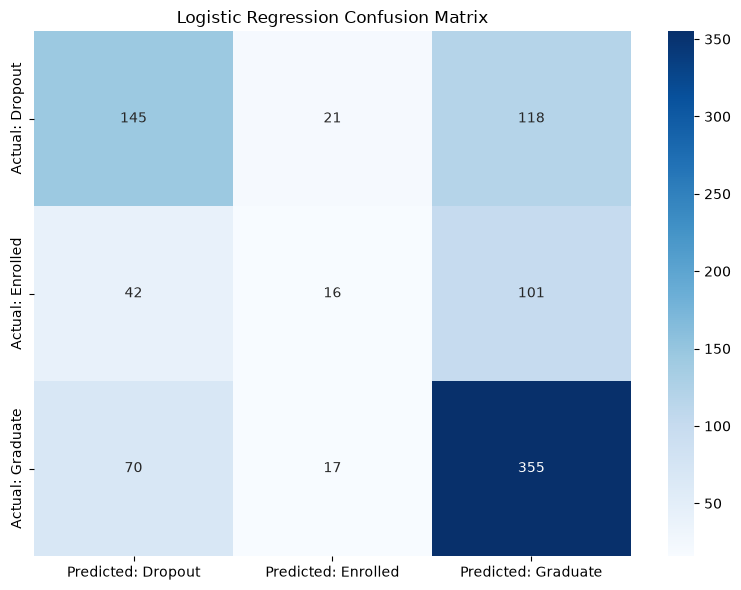

In [13]:
class_labels = ["Dropout", "Enrolled", "Graduate"]

cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=class_labels,
)

cm_logistic_df = pd.DataFrame(
    cm_logistic,
    index=[f"Actual: {label}" for label in class_labels],
    columns=[f"Predicted: {label}" for label in class_labels],
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_logistic_df,
    annot=True,
    fmt="d",
    cmap="Blues",
)

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

## Baseline Comparison

The baseline predicts the most frequent class for every student. Logistic regression uses the selected features to estimate outcome probabilities and make predictions.

We compare both models using the same held-out test set. Accuracy and macro-F1 provide complementary views of their performance.

In [14]:
baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train, y_train)

y_pred_baseline = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test, y_pred_baseline)
baseline_macro_f1 = f1_score(
    y_test,
    y_pred_baseline,
    average="macro",
)

In [15]:
comparison = pd.DataFrame(
    {
        "Model": [
            "Most-frequent baseline",
            "Logistic regression",
        ],
        "Accuracy": [
            baseline_accuracy,
            logistic_accuracy,
        ],
        "Macro-F1": [
            baseline_macro_f1,
            logistic_macro_f1,
        ],
    }
)

display(comparison.round(3))

,Model,Accuracy,Macro-F1
0,Most-frequent baseline,0.499,0.222
1,Logistic regression,0.583,0.462


## Initial Model Comparison: Findings

The most-frequent baseline achieved an accuracy of **0.499** and a macro-F1 score of **0.222**. Logistic regression achieved an accuracy of **0.583** and a macro-F1 score of **0.462** on the same held-out test set.

Logistic regression improved accuracy by 8.4 percentage points and increased macro-F1 by 0.240 compared with the baseline. This indicates that using the selected student features provides more useful predictions than always predicting the most frequent class.

The per-class evaluation shows that performance differs considerably across outcomes. The model identifies **Graduate** students most effectively, with a recall of 0.80 and an F1-score of 0.70. Its performance for **Dropout** is more moderate, with a recall of 0.51 and an F1-score of 0.54. The model struggles to identify **Enrolled** students: recall is only 0.10 and the F1-score is 0.15, meaning that most students in this class are not correctly identified.

Overall, logistic regression is a meaningful improvement over the baseline, but its performance is uneven across the three outcome classes. In particular, its weak performance for Enrolled students limits its usefulness as a balanced three-class classifier. The confusion matrix can be used to examine the specific patterns of misclassification between the outcomes.

These results represent an initial evaluation on the held-out test set. They do not establish that the model will perform equally well on future cohorts or at other institutions. The feature exclusions are provisional, and further model comparison and evaluation are needed before drawing stronger conclusions.


## Decision Tree Classifier

A decision tree is a supervised learning algorithm that makes predictions by learning a sequence of decision rules from the training data.

Unlike logistic regression, a decision tree can capture nonlinear relationships and interactions between features.

We will use the same training and test split and preprocessing approach to evaluate this model against our previous results.

In [16]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(random_state=42)),
    ]
)

In [17]:
decision_tree_model.fit(X_train, y_train)

print("Decision tree pipeline fitted successfully.")

Decision tree pipeline fitted successfully.


In [18]:
y_pred_tree = decision_tree_model.predict(X_test)

print("Number of predictions:", len(y_pred_tree))
print("First 10 predictions:", y_pred_tree[:10])

Number of predictions: 885
First 10 predictions: ['Graduate' 'Graduate' 'Graduate' 'Graduate' 'Graduate' 'Dropout'
 'Enrolled' 'Graduate' 'Graduate' 'Dropout']


## Decision Tree Evaluation

We evaluate the decision tree using accuracy, macro-F1, per-class precision and recall, and a confusion matrix.

These metrics allow us to compare the decision tree's performance with logistic regression and the majority-class baseline.

In [19]:
tree_accuracy = accuracy_score(y_test, y_pred_tree)

tree_macro_f1 = f1_score(
    y_test,
    y_pred_tree,
    average="macro",
)

print(f"Decision tree accuracy: {tree_accuracy:.3f}")
print(f"Decision tree macro-F1: {tree_macro_f1:.3f}")

print("\nPer-class evaluation:")
print(
    classification_report(
        y_test,
        y_pred_tree,
        labels=["Dropout", "Enrolled", "Graduate"],
        zero_division=0,
    )
)

Decision tree accuracy: 0.486
Decision tree macro-F1: 0.429

Per-class evaluation:
              precision    recall  f1-score   support

     Dropout       0.45      0.43      0.44       284
    Enrolled       0.25      0.25      0.25       159
    Graduate       0.59      0.61      0.60       442

    accuracy                           0.49       885
   macro avg       0.43      0.43      0.43       885
weighted avg       0.48      0.49      0.48       885



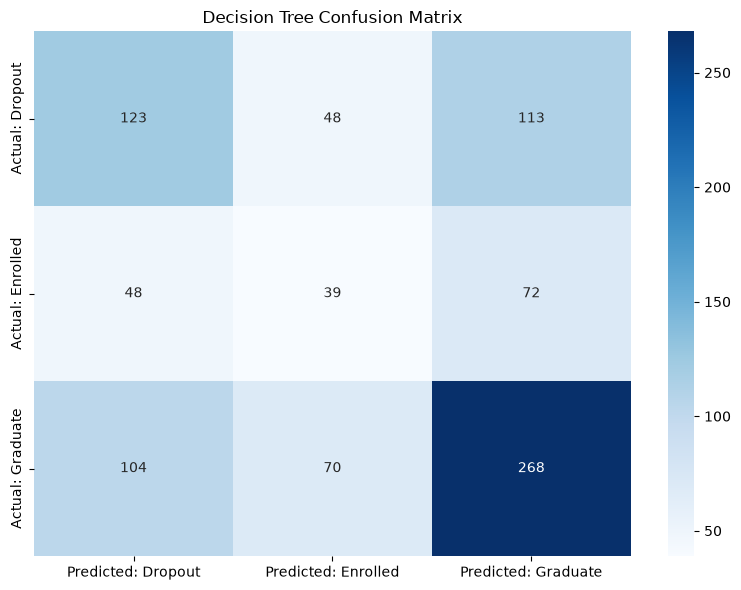

In [20]:
cm_tree = confusion_matrix(
    y_test,
    y_pred_tree,
    labels=class_labels,
)

cm_tree_df = pd.DataFrame(
    cm_tree,
    index=[f"Actual: {label}" for label in class_labels],
    columns=[f"Predicted: {label}" for label in class_labels],
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_tree_df,
    annot=True,
    fmt="d",
    cmap="Blues",
)

plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

## Model Comparison

We compare the most-frequent baseline, logistic regression, and decision tree using the same held-out test set.

Accuracy measures overall correctness, while macro-F1 gives equal importance to each outcome class.

In [21]:
comparison = pd.DataFrame(
    {
        "Model": [
            "Most-frequent baseline",
            "Logistic regression",
            "Decision tree",
        ],
        "Accuracy": [
            baseline_accuracy,
            logistic_accuracy,
            tree_accuracy,
        ],
        "Macro-F1": [
            baseline_macro_f1,
            logistic_macro_f1,
            tree_macro_f1,
        ],
    }
)

display(comparison.round(3))

,Model,Accuracy,Macro-F1
0,Most-frequent baseline,0.499,0.222
1,Logistic regression,0.583,0.462
2,Decision tree,0.486,0.429


## Decision Tree vs. Logistic Regression: Findings

The decision tree achieved an accuracy of **0.486** and a macro-F1 score of **0.429**, compared with **0.583** accuracy and **0.462** macro-F1 for logistic regression.

Although the decision tree improved macro-F1 substantially compared with the most-frequent baseline (0.222), its accuracy was slightly lower than the baseline (0.499).

The per-class evaluation reveals differences between the two models. The decision tree performed better at identifying Enrolled students, achieving an F1-score of 0.25 compared with 0.15 for logistic regression. However, logistic regression performed better for both Dropout (0.54 vs. 0.44) and Graduate (0.70 vs. 0.60).

Overall, logistic regression currently provides the strongest balance of accuracy and macro-F1 across the three classes. The decision tree demonstrates a different pattern of class-level performance, particularly for Enrolled students.

These results suggest that model performance should be evaluated across individual outcome classes rather than relying exclusively on overall accuracy. Further comparison with ensemble methods, particularly random forests, will help determine whether predictive performance can be improved.

## Random Forest Classifier

A Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees.

Each tree is trained using randomized samples of the training data and considers randomized subsets of features when making splits. For classification, the forest combines the trees' predictions through majority voting.

The purpose of this experiment is to investigate whether combining multiple decision trees improves predictive performance compared with logistic regression and a single decision tree.

In [23]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)

In [24]:
random_forest_model.fit(X_train, y_train)

print("Random Forest pipeline fitted successfully.")

Random Forest pipeline fitted successfully.


In [25]:
y_pred_forest = random_forest_model.predict(X_test)

print("Number of predictions:", len(y_pred_forest))
print("First 10 predictions:", y_pred_forest[:10])

Number of predictions: 885
First 10 predictions: ['Graduate' 'Graduate' 'Graduate' 'Graduate' 'Graduate' 'Dropout'
 'Graduate' 'Graduate' 'Graduate' 'Graduate']


## Random Forest Evaluation

We evaluate the Random Forest using accuracy, macro-F1, per-class precision and recall, and a confusion matrix.

These metrics allow us to examine its overall performance and its ability to identify each of the three academic outcomes.

In [26]:
forest_accuracy = accuracy_score(y_test, y_pred_forest)

forest_macro_f1 = f1_score(
    y_test,
    y_pred_forest,
    average="macro",
)

print(f"Random Forest accuracy: {forest_accuracy:.3f}")
print(f"Random Forest macro-F1: {forest_macro_f1:.3f}")

print("\nPer-class evaluation:")
print(
    classification_report(
        y_test,
        y_pred_forest,
        labels=["Dropout", "Enrolled", "Graduate"],
        zero_division=0,
    )
)

Random Forest accuracy: 0.586
Random Forest macro-F1: 0.460

Per-class evaluation:
              precision    recall  f1-score   support

     Dropout       0.55      0.52      0.54       284
    Enrolled       0.41      0.09      0.15       159
    Graduate       0.61      0.81      0.70       442

    accuracy                           0.59       885
   macro avg       0.53      0.47      0.46       885
weighted avg       0.56      0.59      0.55       885



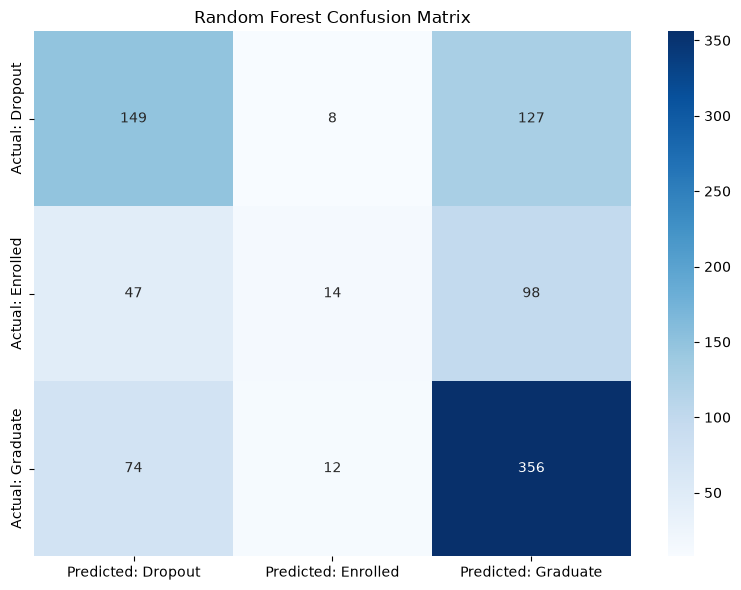

In [27]:
cm_forest = confusion_matrix(
    y_test,
    y_pred_forest,
    labels=class_labels,
)

cm_forest_df = pd.DataFrame(
    cm_forest,
    index=[f"Actual: {label}" for label in class_labels],
    columns=[f"Predicted: {label}" for label in class_labels],
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_forest_df,
    annot=True,
    fmt="d",
    cmap="Blues",
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

In [28]:
comparison = pd.DataFrame(
    {
        "Model": [
            "Most-frequent baseline",
            "Logistic regression",
            "Decision tree",
            "Random Forest",
        ],
        "Accuracy": [
            baseline_accuracy,
            logistic_accuracy,
            tree_accuracy,
            forest_accuracy,
        ],
        "Macro-F1": [
            baseline_macro_f1,
            logistic_macro_f1,
            tree_macro_f1,
            forest_macro_f1,
        ],
    }
)

display(comparison.round(3))

,Model,Accuracy,Macro-F1
0,Most-frequent baseline,0.499,0.222
1,Logistic regression,0.583,0.462
2,Decision tree,0.486,0.429
3,Random Forest,0.586,0.460


## Random Forest vs. Previous Models: Findings

The Random Forest achieved an accuracy of **0.586** and a macro-F1 score of **0.460**.

Compared with the most-frequent baseline, Random Forest substantially improved macro-F1 (0.460 compared with 0.222). Its accuracy (0.586) was also higher than the baseline (0.499).

Compared with logistic regression, Random Forest achieved slightly higher accuracy (0.586 vs. 0.583), while logistic regression achieved a marginally higher macro-F1 score (0.462 vs. 0.460). These differences are small, and neither model demonstrates a clear overall advantage based on these results alone.

The per-class evaluation shows that Random Forest identifies Graduate students relatively well, with a recall of 0.81 and an F1-score of 0.70. Its performance for Dropout is moderate, with a recall of 0.52 and an F1-score of 0.54. However, it struggles to identify Enrolled students: despite achieving a precision of 0.41, its recall is only 0.09 and its F1-score is 0.15.

Overall, Random Forest and logistic regression currently demonstrate very similar performance. Random Forest achieves marginally higher accuracy, while logistic regression achieves marginally higher macro-F1. Both models struggle considerably with the Enrolled class. The decision tree performs worse on overall accuracy and macro-F1, although it identifies Enrolled students more effectively than the other two predictive models.

These findings highlight the importance of evaluating individual outcome classes alongside overall performance. Further validation and model comparison are needed before selecting a final model.